2026-10-05 01:58:57,008 - C:\Users\1\anaconda3\Lib\site-packages\castle\backend\__init__.py[line:36] - INFO: You can use `os.environ['CASTLE_BACKEND'] = backend` to set the backend(`pytorch` or `mindspore`).
2026-10-05 01:58:57,070 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\__init__.py[line:36] - INFO: You are using ``pytorch`` as the backend.


正在生成【虚拟电池产线】复杂测试数据...

[系统安检] 第一关：数据丰度检验...
🟢 完美：N/P比例为 153.8，维度极其健康。

[系统安检] 第二关：缺失值处理...
🔴 剔除：缺失率超 30%的参数：['噪音_无关参数_1']
🟡 修复：启用 MissForest (随机森林) 填补...
🟢 缺失值处理完毕！

[系统安检] 第三关：模型解释力(R^2)测试...
🟢 通关：模型 R^2 为 0.72，高度可信，允许输出报告！

--- 正在执行核心计算：提取 80% 帕累托主因 ---
筛选出累计贡献度达 80% 的核心工艺元凶（共 3 个）：['物理_极片水分', '工艺_压实密度', '工艺_涂布速度']


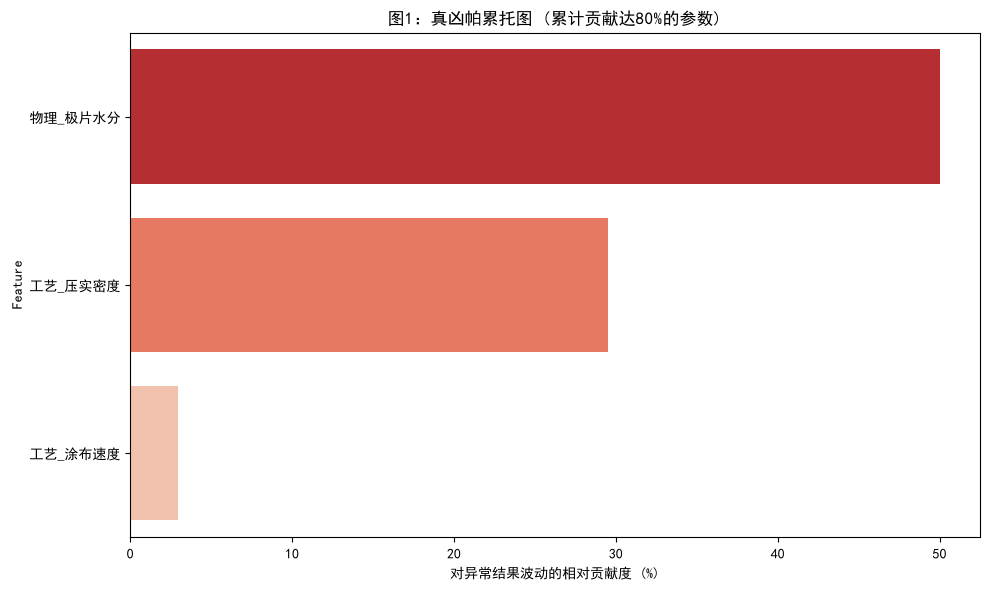


--- 正在绘制协同死角分析图 ---


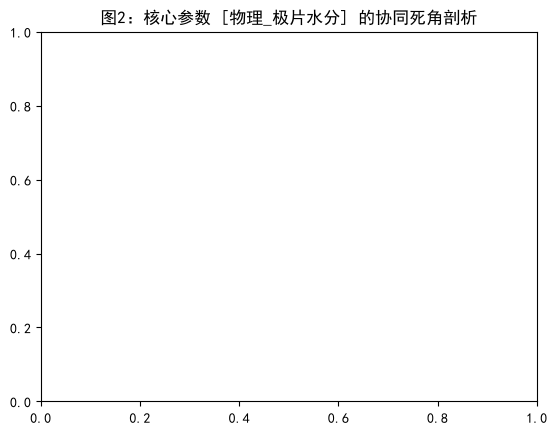

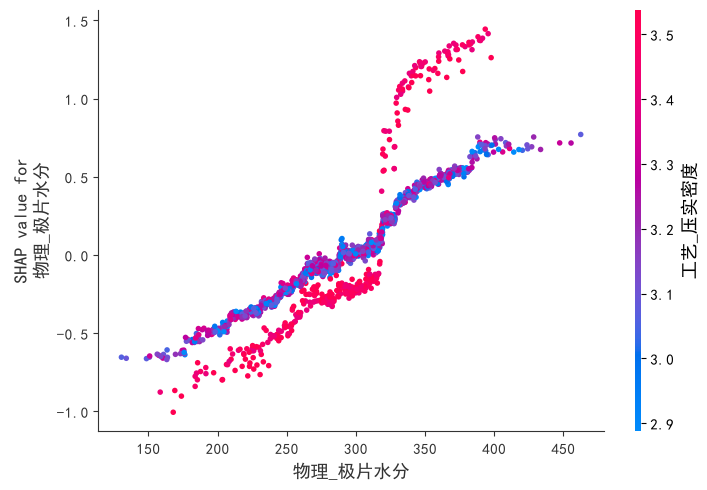

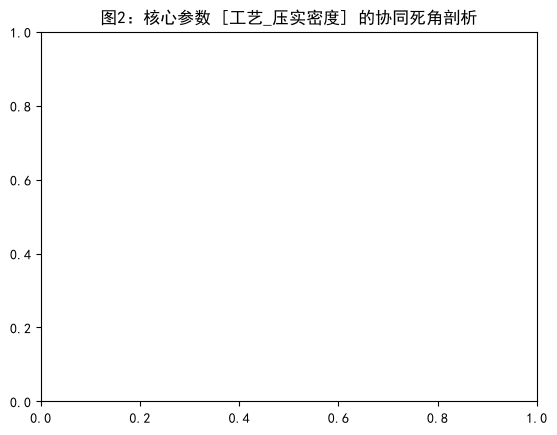

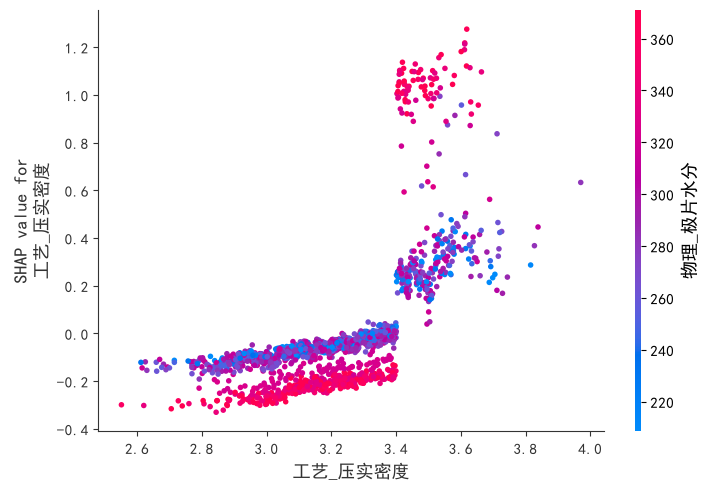

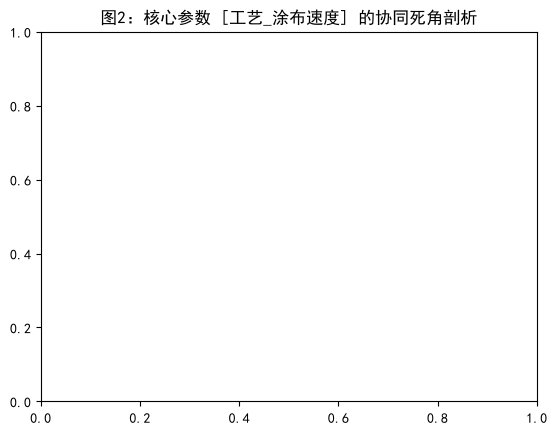

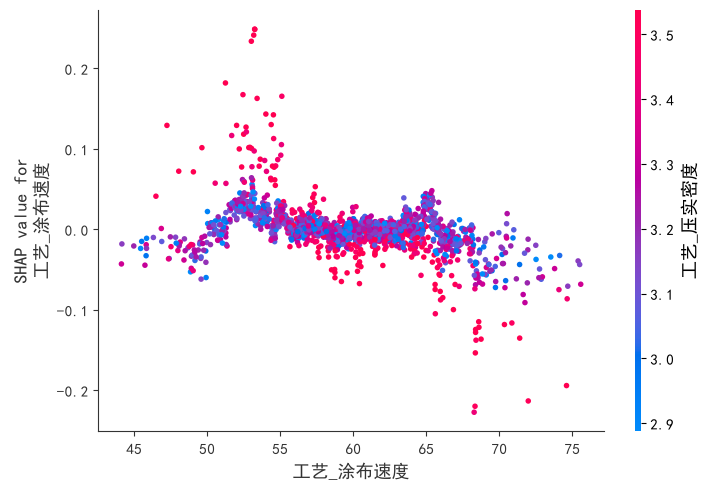

2026-10-05 01:59:02,273 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:195] - INFO: [start]: n=2000, d=14, iter_=100, h_=1e-08, rho_=1e+16
2026-10-05 01:59:02,345 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 0] h=2.293e-01, loss=6.997, rho=1.0e+00
2026-10-05 01:59:02,387 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 1] h=1.575e-01, loss=6.145, rho=1.0e+00
2026-10-05 01:59:02,437 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 1] h=7.312e-02, loss=6.382, rho=1.0e+01



--- 正在生成因果地图 (gCastle) ---


2026-10-05 01:59:02,509 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 1] h=2.249e-02, loss=8.748, rho=1.0e+02
2026-10-05 01:59:02,561 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 2] h=1.317e-02, loss=6.295, rho=1.0e+02
2026-10-05 01:59:02,620 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 2] h=5.569e-03, loss=6.523, rho=1.0e+03
2026-10-05 01:59:02,662 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 3] h=3.711e-03, loss=6.343, rho=1.0e+03
2026-10-05 01:59:02,753 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [iter 3] h=1.684e-03, loss=6.483, rho=1.0e+04
2026-10-05 01:59:02,858 - C:\Users\1\anaconda3\Lib\site-packages\castle\algorithms\gradient\notears\linear.py[line:206] - INFO: [i

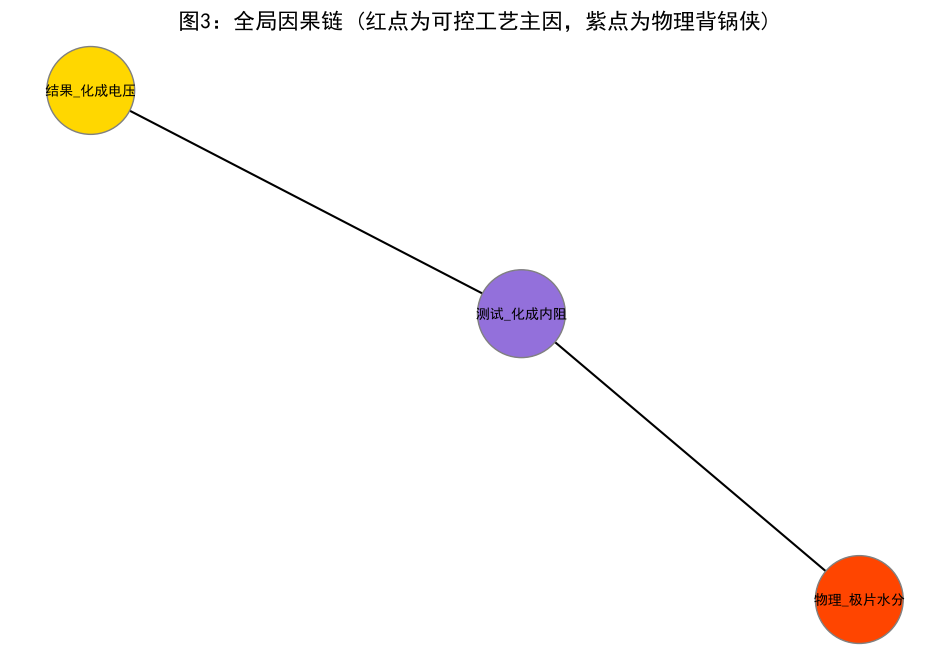

In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import seaborn as sns 
import matplotlib.pyplot as plt
import networkx as nx
from castle.algorithms import Notears
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
import warnings
import re
warnings.filterwarnings('ignore')

#中文显示
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False

# ================= 0. 上帝视角：生成复杂验证数据 =================
print("正在生成【虚拟电池产线】测试数据...")
np.random.seed(42)
N = 2000 # 样本量
compaction = np.random.normal(3.2, 0.2, N)      # 压实密度
moisture = np.random.normal(200, 50, N)         # 极片水分
coating_speed = np.random.normal(60, 5, N)      # 涂布速度 

# 强协同法则：只有当 [压实>3.4] 且 [水分>230] 时，内阻才会爆炸性惩罚
interaction_penalty = np.where((compaction > 3.4) & (moisture > 230), 20, 0)
# 物理因果链：涂布速度 -> 水分 -> 内阻 -> 化成电压
moisture += coating_speed * 1.5 
resistance = 10 + 2 * compaction + 0.05 * moisture + interaction_penalty + np.random.normal(0, 1, N)
voltage = 3.2 + 0.1 * resistance + np.random.normal(0, 0.05, N)

# 组装数据 
df = pd.DataFrame({
    '工艺_涂布速度': coating_speed,
    '工艺_压实密度': compaction,
    '物理_极片水分': moisture,
    '测试_化成内阻': resistance,
    '结果_化成电压': voltage
})
for i in range(1, 11):
    df[f'噪音_无关参数_{i}'] = np.random.normal(0, 1, N)

df.loc[np.random.choice(N, int(N*0.1), replace=False), '物理_极片水分'] = np.nan
df.loc[np.random.choice(N, int(N*0.4), replace=False), '噪音_无关参数_1'] = np.nan

df.columns = [re.sub(r'[":\[\]{}\,]', '_', col) for col in df.columns]

# 定义我们的目标
TARGET = '结果_化成电压'

# 【企业级防呆：破除中间变量陷阱！】
# 我们强制把 '测试_化成内阻' 剔除出 X，逼迫算法去找真正的【工艺和物理源头】
X_for_shap = df.drop(columns=[TARGET, '测试_化成内阻']) 
Y = df[TARGET]


# ================= 1. 第一关：数据量与变异检验 =================
print("\n[系统安检] 第一关：数据丰度检验...")
P = X_for_shap.shape[1]
N_samples = X_for_shap.shape[0]
NP_ratio = N_samples / P

if np.var(Y) < 1e-4:
    raise ValueError("🔴 熔断：目标方差过极小，无需排查。")

if NP_ratio <= 10:
    raise ValueError(f"🔴 熔断：N/P比例过低({NP_ratio:.1f})，停止分析。")
elif NP_ratio <= 50:
    print(f"🟡 警告：N/P比例为 {NP_ratio:.1f}，协同图置信度降低。")
else:
    print(f"🟢 完美：N/P比例为 {NP_ratio:.1f}，维度极其健康。")


# ================= 2. 第二关：缺失值扫描与 MissForest 填补 =================
print("\n[系统安检] 第二关：缺失值处理...")
missing_rates = X_for_shap.isnull().mean()
drop_cols = missing_rates[missing_rates > 0.3].index.tolist()
if drop_cols:
    print(f"🔴 剔除：缺失率超 30%的参数：{drop_cols}")
    X_for_shap = X_for_shap.drop(columns=drop_cols)

if X_for_shap.isnull().sum().sum() > 0:
    print("🟡 修复：启用 MissForest (随机森林) 填补...")
    imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=10, random_state=42), random_state=42)
    X_imputed = pd.DataFrame(imputer.fit_transform(X_for_shap), columns=X_for_shap.columns)
else:
    X_imputed = X_for_shap.copy()
print("🟢 缺失值处理完毕！")


# ================= 3. 第三关：模型 R^2 置信度检验 =================
print("\n[系统安检] 第三关：模型解释力(R^2)测试...")
X_train, X_test, y_train, y_test = train_test_split(X_imputed, Y, test_size=0.2, random_state=42)
model = lgb.train({'objective': 'regression', 'verbose': -1}, lgb.Dataset(X_train, label=y_train))
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

if r2 < 0.3:
    raise ValueError(f"🔴 熔断：模型 R^2 仅为 {r2:.2f}，SHAP 图表不可信！")
print(f"🟢 通关：模型 R^2 为 {r2:.2f}，高度可信，允许输出报告！")


# ================= 4. 模块一：全局 SHAP 与帕累托 80% 截取 =================
print("\n--- 正在执行核心计算：提取 80% 帕累托主因 ---")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_imputed)

shap_abs_mean = np.abs(shap_values).mean(axis=0)
total_impact = np.sum(shap_abs_mean)
shap_percentages = (shap_abs_mean / total_impact) * 100

feature_impacts = pd.DataFrame({
    'Feature': X_imputed.columns,
    'Impact_Pct': shap_percentages
}).sort_values(by='Impact_Pct', ascending=False)

feature_impacts['Cumulative'] = feature_impacts['Impact_Pct'].cumsum()
pareto_features = feature_impacts[feature_impacts['Cumulative'] - feature_impacts['Impact_Pct'] < 80]['Feature'].tolist()

print(f"筛选出累计贡献度达 80% 的核心工艺元凶（共 {len(pareto_features)} 个）：{pareto_features}")

# 绘制图 1
plt.figure(figsize=(10, 6))
plt.title("图1：真凶帕累托图 (累计贡献达80%的参数)")
sns.barplot(x='Impact_Pct', y='Feature', data=feature_impacts[feature_impacts['Feature'].isin(pareto_features)], palette='Reds_r')
plt.xlabel("对异常结果波动的相对贡献度 (%)")
plt.tight_layout()
plt.show()

# 绘制图 2 (自动遍历)
print("\n--- 正在绘制协同死角分析图 ---")
for feat in pareto_features:
    plt.figure()
    plt.title(f"图2：核心参数 [{feat}] 的协同死角剖析")
    shap.dependence_plot(feat, shap_values, X_imputed, show=False)
    plt.tight_layout()
    plt.show()


# ================= 5. 模块二：高亮因果图 =================
print("\n--- 正在生成因果地图 (gCastle) ---")
# 画因果图时，我们要把全量数据（包括被剔除的内阻和填补后的数据）拼回来，才能看到完整链条！
df_causal = X_imputed.copy()
df_causal['测试_化成内阻'] = df['测试_化成内阻'] # 把内阻拿回来当证据节点
df_causal[TARGET] = Y

df_scaled = (df_causal - df_causal.mean()) / df_causal.std()
nt = Notears()
nt.learn(df_scaled)
adj_matrix = nt.causal_matrix

G = nx.DiGraph()
columns = df_causal.columns
for i in range(len(columns)):
    for j in range(len(columns)):
        if adj_matrix[i, j] != 0:
            G.add_edge(columns[i], columns[j])

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)

node_colors = []
for node in G.nodes():
    if node == TARGET:
        node_colors.append('#FFD700') # 金色：最终结果
    elif node in pareto_features:
        node_colors.append('#FF4500') # 红色：帕累托揪出的工艺主因
    elif node == '测试_化成内阻':
        node_colors.append('#9370DB') # 紫色：中间测试结果
    else:
        node_colors.append('#E0E0E0') # 灰色：边缘参数

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=4000, edgecolors='grey')
nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=25, edge_color='black', width=1.5)
nx.draw_networkx_labels(G, pos, font_family='SimHei', font_size=10, font_weight='bold')

plt.title("图3：全局因果链 (红点为可控工艺主因，紫点为表象)", fontsize=16)
plt.axis('off')
plt.show()